Student Name: Priya K

Batch: DSB02

Project Title: Student Dropout and Academic Success Prediction Using Deep Learning

Project Category: Deep Learning

Submission Date:

### Stage 1-Data selection , EDA, data cleaning ,data preprocessing

1. Problem Definition

1.1 Business / Real-World Problem Statement

 Higher education institutions face challenges in identifying students at risk of dropping out. This project develops a Deep Learning-based prediction system to classify students as Dropout, Enrolled, or Graduate using demographic, academic, and socioeconomic data. The system helps institutions identify at-risk students early and provide appropriate academic guidance and support.

 1.2 Project Objectives

* Understand the student dropout and academic success problem.
* Analyze and preprocess student data.
* Develop a Deep Learning model to predict student outcomes.
* Evaluate and compare model performance.
* Deploy the final prediction model.


**Target Users:**

* Educational institutions
* Teachers and academic advisors
* Student support teams
* College administrators


1.4 Input and Expected Output

Input:
Student demographic, academic, and socioeconomic details.

**Expected Output:**
Predicted student outcome: **Dropout, Enrolled, or Graduate**.



## 1.5 Proposed AI Solution
The proposed solution uses a **Deep Learning-based Artificial Neural Network (ANN)** to analyze student demographic, academic, and socioeconomic data. The model learns patterns from historical student records and predicts whether a student is likely to **Dropout, remain Enrolled, or Graduate**. This can help institutions identify students who may need additional academic support.


1.6 Project Category

Deep Learning

Technique / Model: Artificial Neural Network (ANN) for Multiclass Classification

# 2. Dataset Selection & Understanding

2.1 Dataset Source :UCI Machine Learning Repository

Dataset Source: https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success

Data Set Link:https://archive.ics.uci.edu/static/public/697/data.csv

# 2.2 Dataset Description

Number of Records / Samples: 4,424

Number of Features: 36

Number of Classes: 3

Classes: Dropout, Enrolled, Graduate

Dataset Purpose: To predict students’ academic outcomes and identify students at risk of dropping out.

Data Source: UCI Machine Learning Repository

# 2.3 Dataset Overview

Shape

The dataset contains 4,424 records and 36 features.

Info

The dataset contains numerical and categorical features related to students' demographic, academic, and socioeconomic information. There are no missing values.

Describe

Descriptive statistics are used to understand the distribution, mean, minimum, maximum, and other statistical properties of the numerical features.


2.4 Feature / Data Description

| **Feature**                  | **Data Type**       | **Description**                                  |
| ---------------------------- | ------------------- | ------------------------------------------------ |
| Marital Status               | Numeric/Categorical | Student's marital status                         |
| Application Mode             | Numeric             | Method used to apply for admission               |
| Application Order            | Numeric             | Order in which the application was submitted     |
| Course                       | Numeric/Categorical | Student's enrolled course                        |
| Daytime/Evening Attendance   | Numeric/Categorical | Student's attendance schedule                    |
| Previous Qualification       | Numeric/Categorical | Student's previous qualification                 |
| Previous Qualification Grade | Numeric             | Grade obtained in previous qualification         |
| Nationality                  | Numeric/Categorical | Student's nationality                            |
| Mother's Qualification       | Numeric/Categorical | Mother's education qualification                 |
| Father's Qualification       | Numeric/Categorical | Father's education qualification                 |
| Admission Grade              | Numeric             | Grade obtained during admission                  |
| Displaced                    | Numeric/Categorical | Whether the student is displaced                 |
| Educational Special Needs    | Numeric/Categorical | Indicates special educational needs              |
| Debtor                       | Numeric/Categorical | Indicates whether the student has financial debt |
| Tuition Fees Up to Date      | Numeric/Categorical | Indicates whether tuition fees are paid          |
| Gender                       | Numeric/Categorical | Student's gender                                 |
| Scholarship Holder           | Numeric/Categorical | Indicates scholarship status                     |
| Age at Enrollment            | Numeric             | Student's age at enrollment                      |
| Curricular Units 1st Sem     | Numeric             | Academic performance in first semester           |
| Curricular Units 2nd Sem     | Numeric             | Academic performance in second semester          |
| Unemployment Rate            | Numeric             | Unemployment rate                                |
| Inflation Rate               | Numeric             | Inflation rate                                   |
| GDP                          | Numeric             | Gross Domestic Product indicator                 |
| Target                       | Categorical         | Academic outcome: Dropout, Enrolled, or Graduate |


2.5 Target Variable / Class

Name: Target: Target Variable Format: Categorical (3 classes)

0 – Dropout
1 – Enrolled
2 – Graduate

Description: Student's academic outcome with three classes: Dropout, Enrolled, and Graduate.

Prediction Goal: Predict the student's academic outcome using demographic, academic, and socioeconomic features.

3. Exploratory Data Analysis

3.1 Import Libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, GridSearchCV, RandomizedSearchCV, StratifiedKFold
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.regularizers import l2

# Reproducibility
tf.keras.utils.set_random_seed(42)


3.2 Load Dataset

In [4]:
# Load dataset
df = pd.read_csv("https://archive.ics.uci.edu/static/public/697/data.csv")

# Display first 5 records
df.head()

,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


3.3 Dataset Analysis


Shape

Info

Describe

In [5]:
df.shape

(4424, 37)

In [6]:
df.info()  #checks the dataset structure, data types, and missing values

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital Status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                   

In [7]:
df.describe() # helps understand the statistical distribution of numerical data.

,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,...,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,1.178571,18.669078,1.727848,8856.642631,0.890823,4.577758,132.613314,1.873192,19.561935,22.275316,...,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,0.605747,17.484682,1.313793,2063.566416,0.311897,10.216592,13.188332,6.914514,15.603186,15.343108,...,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,1.000000,1.000000,0.000000,33.000000,0.000000,1.000000,95.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,1.000000,9085.000000,1.000000,1.000000,125.000000,1.000000,2.000000,3.000000,...,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,1.000000,17.000000,1.000000,9238.000000,1.000000,1.000000,133.100000,1.000000,19.000000,19.000000,...,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,1.000000,39.000000,2.000000,9556.000000,1.000000,1.000000,140.000000,1.000000,37.000000,37.000000,...,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,6.000000,57.000000,9.000000,9991.000000,1.000000,43.000000,190.000000,109.000000,44.000000,44.000000,...,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


Shape: Shows the number of rows and columns.

Info: Shows data types and non-null values.

Describe: Shows statistical summary of numerical features.

In [8]:
df.head()

,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [9]:
df.tail()

,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
4419,1,1,6,9773,1,1,125.0,1,1,1,...,0,6,8,5,12.666667,0,15.5,2.8,-4.06,Graduate
4420,1,1,2,9773,1,1,120.0,105,1,1,...,0,6,6,2,11.000000,0,11.1,0.6,2.02,Dropout
4421,1,1,1,9500,1,1,154.0,1,37,37,...,0,8,9,1,13.500000,0,13.9,-0.3,0.79,Dropout
4422,1,1,1,9147,1,1,180.0,1,37,37,...,0,5,6,5,12.000000,0,9.4,-0.8,-3.12,Graduate
4423,1,10,1,9773,1,1,152.0,22,38,37,...,0,6,6,6,13.000000,0,12.7,3.7,-1.70,Graduate


In [10]:
df.columns

Index(['Marital Status', 'Application mode', 'Application order', 'Course',
       'Daytime/evening attendance', 'Previous qualification',
       'Previous qualification (grade)', 'Nacionality',
       'Mother's qualification', 'Father's qualification',
       'Mother's occupation', 'Father's occupation', 'Admission grade',
       'Displaced', 'Educational special needs', 'Debtor',
       'Tuition fees up to date', 'Gender', 'Scholarship holder',
       'Age at enrollment', 'International',
       'Curricular units 1st sem (credited)',
       'Curricular units 1st sem (enrolled)',
       'Curricular units 1st sem (evaluations)',
       'Curricular units 1st sem (approved)',
       'Curricular units 1st sem (grade)',
       'Curricular units 1st sem (without evaluations)',
       'Curricular units 2nd sem (credited)',
       'Curricular units 2nd sem (enrolled)',
       'Curricular units 2nd sem (evaluations)',
       'Curricular units 2nd sem (approved)',
       'Curricular units 2nd s

3.4 Missing Value Analysis

In [11]:
df.isnull().sum()

,0
Marital Status,0
Application mode,0
Application order,0
Course,0
Daytime/evening attendance,0
Previous qualification,0
Previous qualification (grade),0
Nacionality,0
Mother's qualification,0
Father's qualification,0




Observation: The dataset contains no missing values, so no missing-value imputation is required.

3.5 Class Distribution

In [12]:
class_counts = df['Target'].value_counts()

print(class_counts)

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


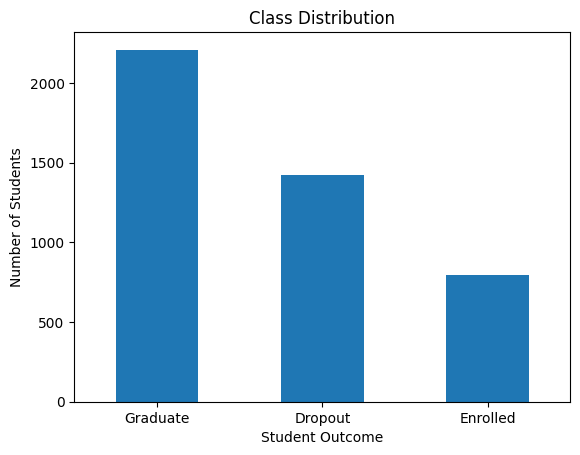

In [13]:
# Visualize class distribution

class_counts.plot(kind='bar')
plt.title('Class Distribution')
plt.xlabel('Student Outcome')
plt.ylabel('Number of Students')
plt.xticks(rotation=0)
plt.show()

Observation:

The target variable contains three classes: Dropout, Enrolled, and Graduate. The classes are imbalanced, with different numbers of students in each category.

3.6 Correlation / Relationship Analysis

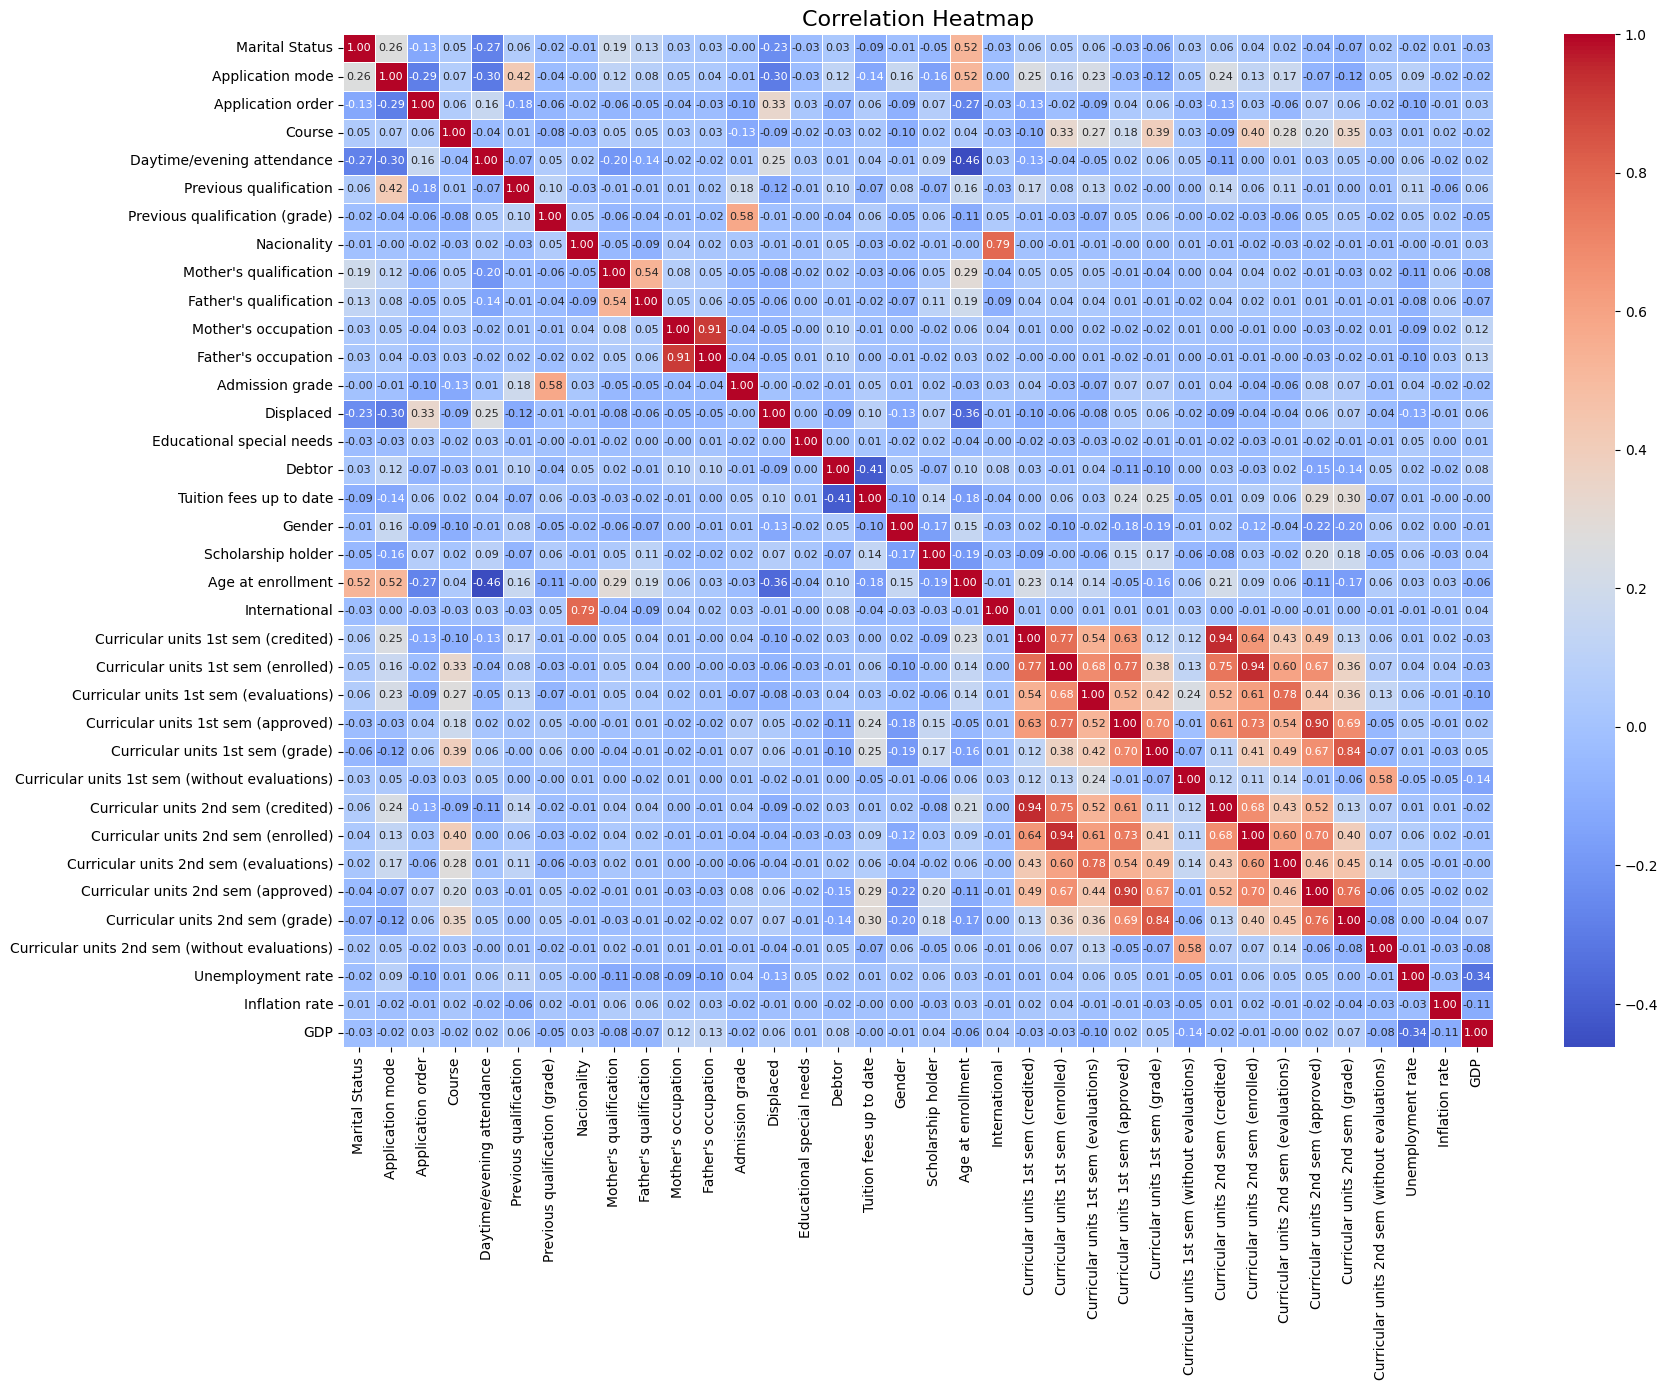

In [14]:
# Correlation matrix
correlation = df.corr(numeric_only=True)

# Plot correlation heatmap with numbers
plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    annot=True,          # Show correlation values
    fmt=".2f",           # Show 2 decimal places
    linewidths=0.5,
    annot_kws={"size": 8}
)

plt.title("Correlation Heatmap", fontsize=16)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

Observation:

The correlation heatmap helps identify relationships between numerical features and the target variable. It can also highlight highly correlated features that may provide useful information for the prediction model.

3.7 Visualizations

Visualization 1 – Student Outcome Distribution




This plot shows the distribution of students across the three academic outcomes. It helps us understand the class distribution before building the prediction model

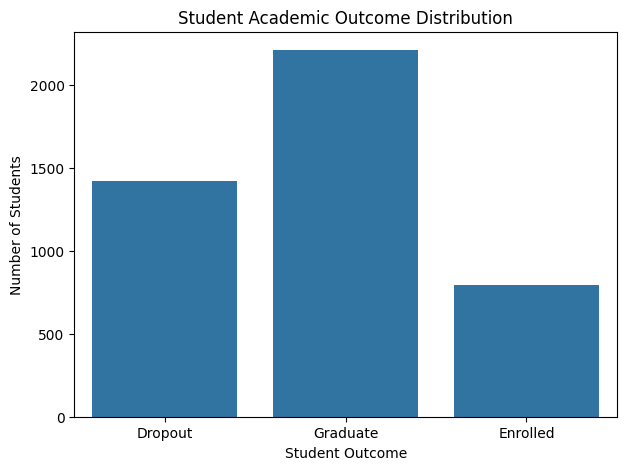

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Plot student outcome distribution using the original 'Target' column in df
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Target')

plt.title('Student Academic Outcome Distribution')
plt.xlabel('Student Outcome')
plt.ylabel('Number of Students')
plt.show()

Observation:

The plot shows the distribution of students across Dropout, Enrolled, and Graduate categories. The target classes are imbalanced, which should be considered during model training and evaluation.


Visualization 2 – Student Academic Outcome Percentage

This pie chart represents the percentage of students in each academic outcome. It helps us quickly understand the proportion of Dropout, Enrolled, and Graduate students

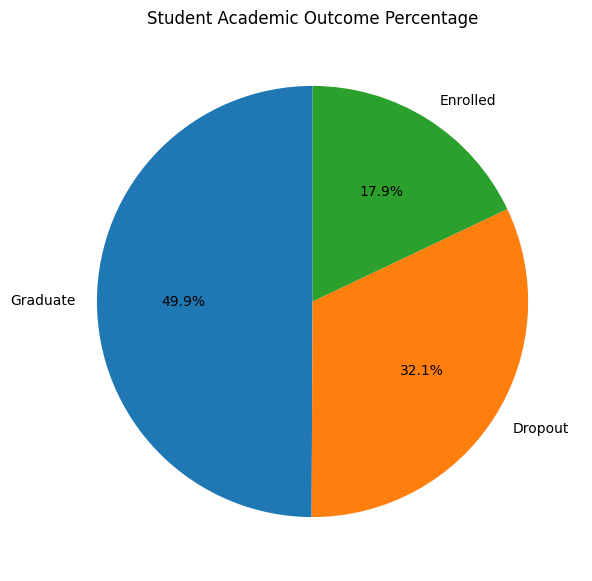

In [16]:
plt.figure(figsize=(7, 7))

df['Target'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Student Academic Outcome Percentage')
plt.ylabel('')
plt.show()

Observation:

 the percentage distribution of students across the three academic outcomes: Dropout, Enrolled, and Graduate. It provides a clear view of the proportion of students belonging to each outcome category and helps identify differences in the class distribution.


Purpose: Analyze whether academic outcomes

Visualization 3 – Outcome by Age at Enrollment

This histogram shows the distribution of students' ages at the time of enrollment. It helps us understand the common age range of students and how the ages are distributed across the dataset

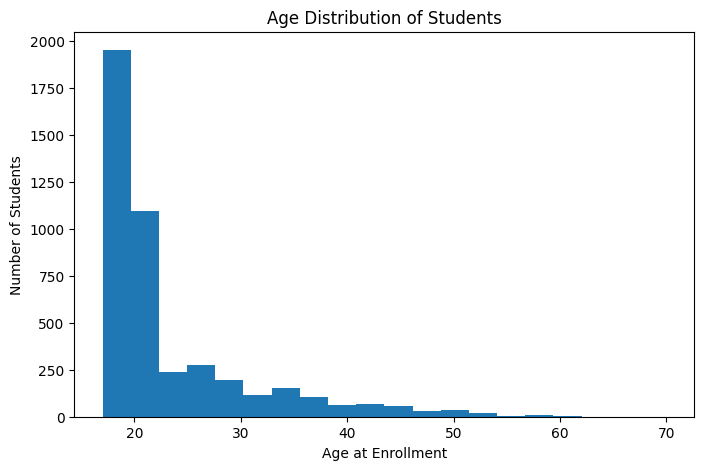

In [17]:
plt.figure(figsize=(8, 5))

plt.hist(df['Age at enrollment'], bins=20)

plt.title('Age Distribution of Students')
plt.xlabel('Age at Enrollment')
plt.ylabel('Number of Students')
plt.show()

Observations:
 the distribution of students based on their age at enrollment. Most students are concentrated within the younger age ranges, while fewer students are enrolled at older ages. This visualization helps understand the age pattern of the students in the dataset.


Purpose: Examine the age distribution across different student outcomes.

Visualization 4 – Admission Grade by Outcome

This boxplot compares admission grades across the three student outcomes. It helps us understand whether admission grade has a relationship with student academic outcome

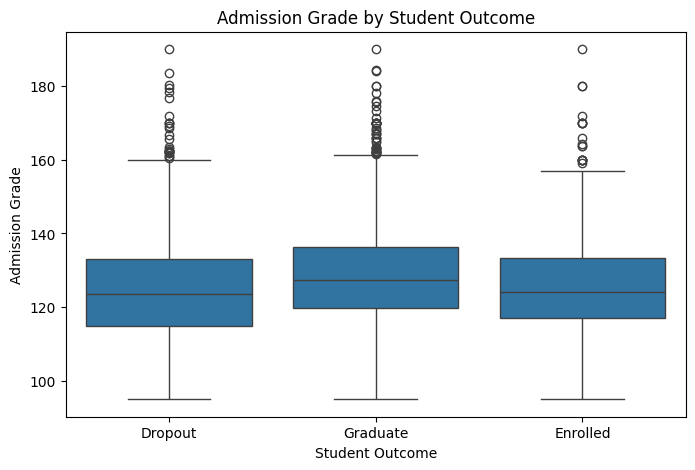

In [18]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Target', y='Admission grade', data=df)
plt.title('Admission Grade by Student Outcome')
plt.xlabel('Student Outcome')
plt.ylabel('Admission Grade')
plt.show()

Observation: The plot compares admission grades across Dropout, Enrolled, and Graduate students, highlighting differences in median, spread, and outliers that may relate to academic outcomes.

Visualization  5– Age vs Admission Grade.

This plot shows Age at Enrollment versus Admission Grade. Each point represents a student, and the colors represent their academic outcome. It helps us identify whether there is any visible relationship or pattern between age and admission grade

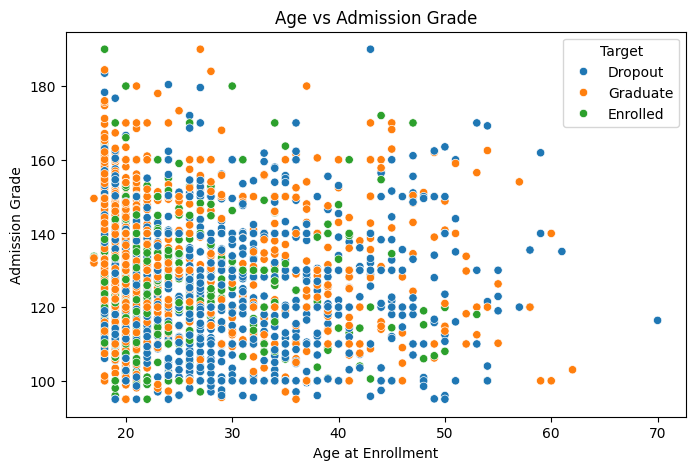

In [19]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Age at enrollment',
    y='Admission grade',
    hue='Target'
)

plt.title('Age vs Admission Grade')
plt.xlabel('Age at Enrollment')
plt.ylabel('Admission Grade')
plt.show()

Observation: The plot compares age at enrollment and admission grade across Dropout, Enrolled, and Graduate students to identify patterns associated with academic outcomes.

Visualization 6 – Previous Qualification Grade by Outcome

This plot compares previous qualification grades across the three student outcomes. The width of each violin shows where the students are more concentrated, helping us understand the distribution of grades for each group

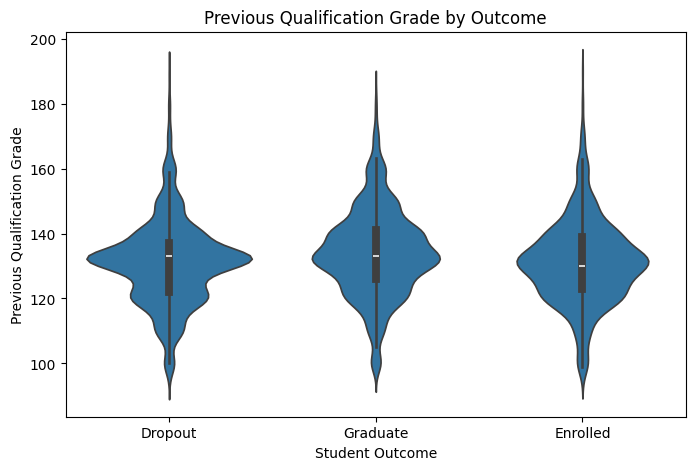

In [20]:

plt.figure(figsize=(8, 5))

sns.violinplot(
    x ='Target',
    y ='Previous qualification (grade)',
    data=df
)

plt.title('Previous Qualification Grade by Outcome')
plt.xlabel('Student Outcome')
plt.ylabel('Previous Qualification Grade')
plt.show()

Observation: The plot compares academic outcomes of scholarship holders and non-scholarship holders, showing that scholarship status may be associated with student academic outcomes.

Visualization 7 – Scholarship Status vs Outcome

This plot compares scholarship status with student outcomes. It helps us see how Dropout, Enrolled, and Graduate students are distributed among scholarship holders and non-scholarship holders

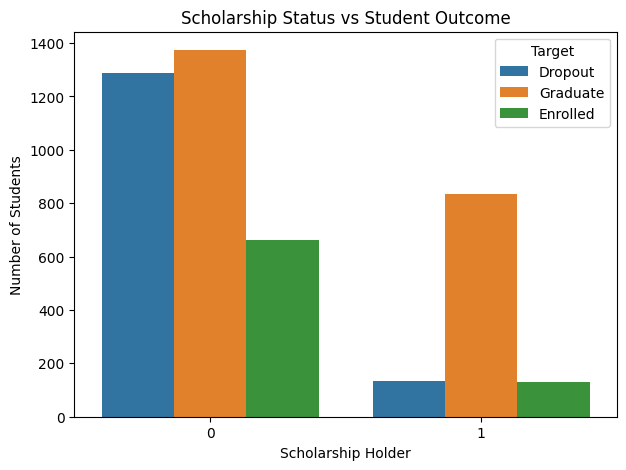

In [21]:
plt.figure(figsize=(7, 5))
sns.countplot(x='Scholarship holder', hue='Target', data=df)
plt.title('Scholarship Status vs Student Outcome')
plt.xlabel('Scholarship Holder')
plt.ylabel('Number of Students')
plt.show()

Observation: The plot compares academic outcomes based on tuition fee payment status, suggesting that fee payment may be associated with student academic outcomes.

Visualization 8 – First Semester Approved Units by Outcome

This plot compares the number of first-semester approved units across the three student outcomes. It helps us understand whether early academic performance is associated with dropout, enrollment, or graduation

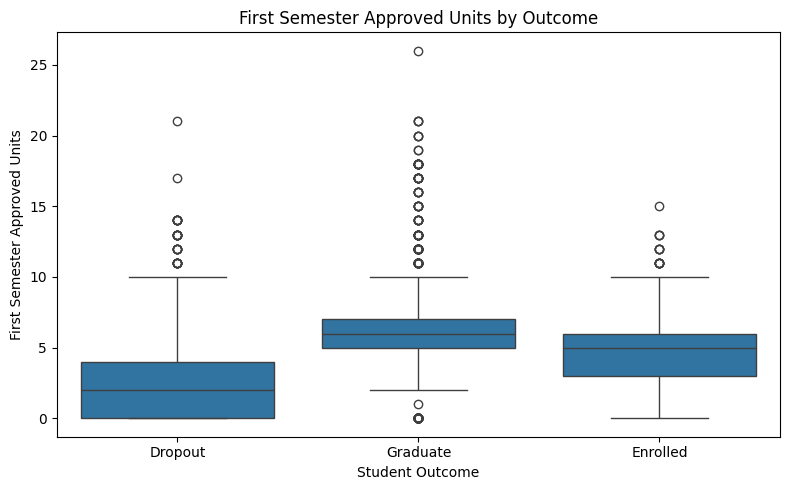

In [22]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    x='Target',
    y='Curricular units 1st sem (approved)',
    data=df
)

plt.title('First Semester Approved Units by Outcome')
plt.xlabel('Student Outcome')
plt.ylabel('First Semester Approved Units')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

Observation: The boxplot compares first-semester approved curricular units across Dropout, Enrolled, and Graduate students, helping identify the relationship between first-semester academic performance and student outcomes.

Visualization 9 – Average Approved Units by Semester

This plot compares the average approved curricular units in the first and second semesters across Dropout, Enrolled, and Graduate students. It helps us understand whether semester-wise academic performance is associated with student outcomes

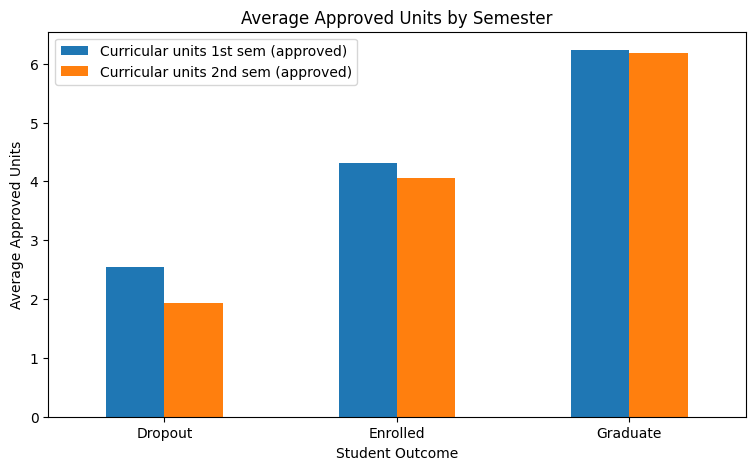

In [23]:

semester_data = df.groupby('Target')[
    ['Curricular units 1st sem (approved)',
     'Curricular units 2nd sem (approved)']
].mean()

semester_data.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Average Approved Units by Semester')
plt.xlabel('Student Outcome')
plt.ylabel('Average Approved Units')
plt.xticks(rotation=0)
plt.show()

Observation: Students with more approved curricular units in the first and second semesters generally show better academic outcomes, while fewer approved units are associated with a higher risk of dropout.

Visualization 10 -Gender Distribution by Student Outcome

This plot shows the distribution of male and female students across Dropout, Enrolled, and Graduate categories. It helps us understand whether there are noticeable differences in student outcomes across gender groups

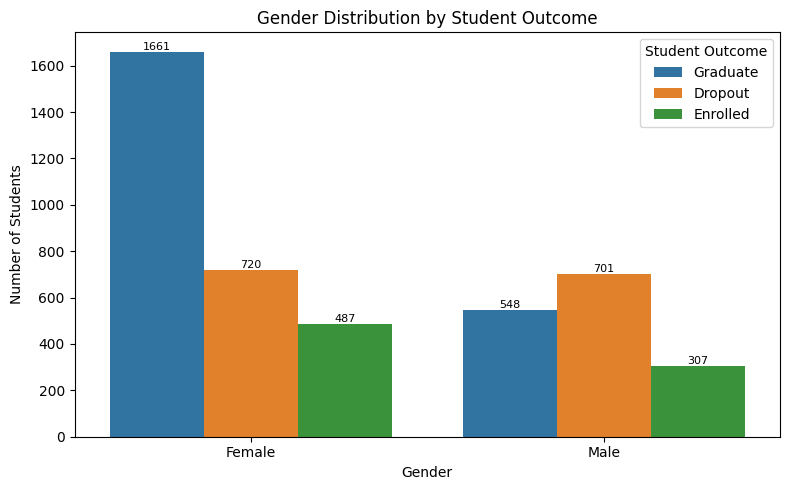

In [24]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    x='Gender',
    hue='Target',
    data=df
)

plt.title('Gender Distribution by Student Outcome')
plt.xlabel('Gender')
plt.ylabel('Number of Students')

plt.xticks(
    ticks=[0, 1],
    labels=['Female', 'Male']
)

for container in ax.containers:
    ax.bar_label(container, fontsize=8)

plt.legend(title='Student Outcome')

plt.tight_layout()
plt.show()

Observation:

The heatmap shows positive and negative correlations among the numerical features. Highly correlated features can provide useful information for feature selection and model development.

# 4. Data Cleaning & Preprocessing


4.1 Missing Value Treatment

In [25]:
missing_values = df.isnull().sum()
print(missing_values)

Marital Status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance                        0
Previous qualification                            0
Previous qualification (grade)                    0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Admission grade                                   0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder                                0
Age at enrol

In [26]:
print("\nTotal Missing Values:", df.isnull().sum().sum())


Total Missing Values: 0


Imputation
No imputation was required because df.isnull().sum() confirmed that the dataset contains no missing values. Therefore, all records were retained for further preprocessing and model development.

4.2 Duplicate Handling

In [27]:
duplicate_count = df.duplicated().sum()

In [28]:
duplicate_count

np.int64(0)

In [29]:
df = df.drop_duplicates()

In [30]:
df

,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4419,1,1,6,9773,1,1,125.0,1,1,1,...,0,6,8,5,12.666667,0,15.5,2.8,-4.06,Graduate
4420,1,1,2,9773,1,1,120.0,105,1,1,...,0,6,6,2,11.000000,0,11.1,0.6,2.02,Dropout
4421,1,1,1,9500,1,1,154.0,1,37,37,...,0,8,9,1,13.500000,0,13.9,-0.3,0.79,Dropout
4422,1,1,1,9147,1,1,180.0,1,37,37,...,0,5,6,5,12.000000,0,9.4,-0.8,-3.12,Graduate


In [31]:
print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (4424, 37)


Observation:

The dataset was checked for duplicate records. Any duplicate rows, if present, were removed to avoid repeated observations and ensure that each student record is considered only once during model training.

4.3 Outlier Treatment

In [32]:
# Identify categorical columns
categorical_columns = [
    'Marital status', 'Application mode', 'Application order',
    'Course', 'Daytime/evening attendance',
    'Previous qualification', 'Nacionality',
    "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation",
    'Displaced', 'Educational special needs', 'Debtor',
    'Tuition fees up to date', 'Gender', 'Scholarship holder',
    'International'
]

categorical_columns = [c for c in categorical_columns if c in df.columns]

# Identify numerical columns
numeric_columns = [
    c for c in df.select_dtypes(include='number').columns
    if c != 'Target' and c not in categorical_columns
]

# Count potential outliers using IQR
for col in numeric_columns:
    Q1, Q3 = df[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    count = ((df[col] < Q1 - 1.5 * IQR) |
             (df[col] > Q3 + 1.5 * IQR)).sum()
    print(f"{col}: {count} potential outliers")

Marital Status: 505 potential outliers
Previous qualification (grade): 179 potential outliers
Admission grade: 86 potential outliers
Age at enrollment: 441 potential outliers
Curricular units 1st sem (credited): 577 potential outliers
Curricular units 1st sem (enrolled): 424 potential outliers
Curricular units 1st sem (evaluations): 158 potential outliers
Curricular units 1st sem (approved): 180 potential outliers
Curricular units 1st sem (grade): 726 potential outliers
Curricular units 1st sem (without evaluations): 294 potential outliers
Curricular units 2nd sem (credited): 530 potential outliers
Curricular units 2nd sem (enrolled): 369 potential outliers
Curricular units 2nd sem (evaluations): 109 potential outliers
Curricular units 2nd sem (approved): 44 potential outliers
Curricular units 2nd sem (grade): 877 potential outliers
Curricular units 2nd sem (without evaluations): 282 potential outliers
Unemployment rate: 0 potential outliers
Inflation rate: 0 potential outliers
GDP: 0 

Method Used:

Interquartile Range (IQR) method.

Observation:
The IQR method was used to identify potential outliers in numerical features. Since these values may represent valid student characteristics, no outliers were automatically removed, and all records were retained for further preprocessing and model development.

In [33]:
print("Data types:\n", df.dtypes)
print("Dataset shape:", df.shape)

categorical_columns = [c for c in [
    'Marital status', 'Application mode', 'Application order',
    'Course', 'Daytime/evening attendance', 'Previous qualification',
    'Nacionality', "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation", 'Displaced',
    'Educational special needs', 'Debtor', 'Tuition fees up to date',
    'Gender', 'Scholarship holder', 'International'
] if c in df.columns]

print("Categorical columns:", categorical_columns)

for col in categorical_columns:
    print(f"\n{col}\n", df[col].value_counts().head(10))

Data types:
 Marital Status                                      int64
Application mode                                    int64
Application order                                   int64
Course                                              int64
Daytime/evening attendance                          int64
Previous qualification                              int64
Previous qualification (grade)                    float64
Nacionality                                         int64
Mother's qualification                              int64
Father's qualification                              int64
Mother's occupation                                 int64
Father's occupation                                 int64
Admission grade                                   float64
Displaced                                           int64
Educational special needs                           int64
Debtor                                              int64
Tuition fees up to date                             int64
G

4.4 Encoding


In [34]:
# Keep the original Target text labels in df.
# The single LabelEncoder is fitted once in Cell 99, before the train/validation/test split.
print("Original target classes:", sorted(df["Target"].astype(str).unique()))
print("Target counts:")
print(df["Target"].value_counts())


Original target classes: ['Dropout', 'Enrolled', 'Graduate']
Target counts:
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


Method Used:

Label Encoding was used for the target variable because it contains three categorical classes: Dropout, Enrolled, and Graduate.

Categorical input features can be converted into numerical form using One-Hot Encoding during the preprocessing stage.





4.5 Scaling / Normalization

In [35]:
# Imports, target encoding, and stratified train/validation/test split
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Keep Target as a single multiclass column; do NOT one-hot encode it.
X = df.drop(columns=["Target"]).copy()
target_text = df["Target"].astype(str).copy()
le = LabelEncoder()
y = le.fit_transform(target_text)  # consistent integer labels: 0, 1, 2
print("Target mapping:", dict(zip(le.classes_, le.transform(le.classes_))))

# 70% train, 15% validation, 15% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)
print("Train:", X_train.shape, "Validation:", X_val.shape, "Test:", X_test.shape)


Target mapping: {'Dropout': np.int64(0), 'Enrolled': np.int64(1), 'Graduate': np.int64(2)}
Train: (3096, 36) Validation: (664, 36) Test: (664, 36)


In [36]:
# Encode coded categorical input features and scale numerical input features.
# Fit the preprocessor on X_train only to avoid data leakage.
categorical_cols = [
    "Marital status", "Application mode", "Application order", "Course",
    "Daytime/evening attendance", "Previous qualification", "Nacionality",
    "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation", "Displaced",
    "Educational special needs", "Debtor", "Tuition fees up to date",
    "Gender", "Scholarship holder", "International"
]
categorical_cols = [c for c in categorical_cols if c in X_train.columns]
numerical_cols = [c for c in X_train.columns if c not in categorical_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numerical_cols)
    ],
    remainder="drop"
)

X_train_transformed = preprocessor.fit_transform(X_train)
X_val_transformed = preprocessor.transform(X_val)
X_test_transformed = preprocessor.transform(X_test)

# Keras works most reliably with dense NumPy arrays.
X_train_processed = (X_train_transformed.toarray()
                     if hasattr(X_train_transformed, "toarray")
                     else np.asarray(X_train_transformed))
X_val_processed = (X_val_transformed.toarray()
                   if hasattr(X_val_transformed, "toarray")
                   else np.asarray(X_val_transformed))
X_test_processed = (X_test_transformed.toarray()
                    if hasattr(X_test_transformed, "toarray")
                    else np.asarray(X_test_transformed))

# Targets remain 1-D integer class labels for all models.
y_train = np.asarray(y_train, dtype=np.int64)
y_val = np.asarray(y_val, dtype=np.int64)
y_test = np.asarray(y_test, dtype=np.int64)

print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)
print("Processed shapes:", X_train_processed.shape, X_val_processed.shape, X_test_processed.shape)
print("Target shapes:", y_train.shape, y_val.shape, y_test.shape)


Categorical columns: ['Application mode', 'Application order', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International']
Numerical columns: ['Marital Status', 'Previous qualification (grade)', 'Admission grade', 'Age at enrollment', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflat

Method Used:
StandardScaler was used to standardize the input features.


4.6 Project-Specific Preprocessing

In [37]:
# Do not one-hot encode Target. Keep the single integer target created in Cell 99.
# Input categorical features are one-hot encoded by the ColumnTransformer in Cell 100.
print("Target classes:", list(le.classes_))
print("Integer target labels:", sorted(np.unique(y_train).tolist()))


Target classes: ['Dropout', 'Enrolled', 'Graduate']
Integer target labels: [0, 1, 2]


In [38]:
print(df.head())

   Marital Status  Application mode  Application order  Course  \
0               1                17                  5     171   
1               1                15                  1    9254   
2               1                 1                  5    9070   
3               1                17                  2    9773   
4               2                39                  1    8014   

   Daytime/evening attendance  Previous qualification  \
0                           1                       1   
1                           1                       1   
2                           1                       1   
3                           1                       1   
4                           0                       1   

   Previous qualification (grade)  Nacionality  Mother's qualification  \
0                           122.0            1                      19   
1                           160.0            1                       1   
2                           122.0     

In [39]:
print(df.dtypes)

Marital Status                                      int64
Application mode                                    int64
Application order                                   int64
Course                                              int64
Daytime/evening attendance                          int64
Previous qualification                              int64
Previous qualification (grade)                    float64
Nacionality                                         int64
Mother's qualification                              int64
Father's qualification                              int64
Mother's occupation                                 int64
Father's occupation                                 int64
Admission grade                                   float64
Displaced                                           int64
Educational special needs                           int64
Debtor                                              int64
Tuition fees up to date                             int64
Gender        

Method Used: One-Hot Encoding for categorical features and StandardScaler for numerical features.

Justification: Encoding converts categorical data into numerical form, while scaling standardizes numerical features for effective ANN training.

4.7 Train / Validation / Test Split

SUMMARY:
- X contains input features used to predict student academic outcomes.
- y contains the target variable: Dropout, Enrolled, or Graduate.
- The dataset is prepared for model training.

In [40]:
# The train/validation/test split was already created in Cell 99.
# Do not split again and do not create one-hot target columns.
print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Testing set:", X_test.shape, y_test.shape)


Training set: (3096, 36) (3096,)
Validation set: (664, 36) (664,)
Testing set: (664, 36) (664,)


Justification:
The dataset is split into training, validation, and testing sets to train, tune, and evaluate the ANN model. stratify=y maintains a similar distribution of Dropout, Enrolled, and Graduate classes across all sets.

# PHASE 2 – FEATURE EXTRACTION & MODEL BUILDING

5. Feature Engineering / Representation

5.1 Feature Engineering

Explain the new features or representations created.

The demographic, academic, and socioeconomic features were retained. Categorical features were encoded, numerical features were standardized, and the Target variable was encoded into three classes: Dropout, Enrolled, and Graduate. The processed data was prepared for ANN model training.

# 5.2 Feature Extraction / Representation Techniques Used


In [41]:
# Exploratory correlations between numeric input columns and encoded target labels.

numeric_for_corr = X.select_dtypes(include=np.number).copy()
numeric_for_corr["_target_encoded"] = np.asarray(y, dtype=np.int64)
target_corr = numeric_for_corr.corr(numeric_only=True)["_target_encoded"].drop("_target_encoded").sort_values()
print("Exploratory numeric-feature correlations with encoded Target:")
print(target_corr)


Exploratory numeric-feature correlations with encoded Target:
Age at enrollment                                -0.243438
Debtor                                           -0.240999
Gender                                           -0.229270
Application mode                                 -0.221747
Curricular units 2nd sem (without evaluations)   -0.094028
Marital Status                                   -0.089804
Curricular units 1st sem (without evaluations)   -0.068702
Previous qualification                           -0.056039
Mother's qualification                           -0.043178
Inflation rate                                   -0.026874
Nacionality                                      -0.014801
Educational special needs                        -0.007353
Mother's occupation                              -0.005629
Father's occupation                              -0.001899
Father's qualification                           -0.001393
International                                     0.0

In [42]:
import numpy as np

corr_matrix = X.select_dtypes(include=np.number).corr()

high_corr = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
).stack()

high_corr = high_corr[high_corr.abs() > 0.90]

print(high_corr)

Mother's occupation                  Father's occupation                    0.910472
Curricular units 1st sem (credited)  Curricular units 2nd sem (credited)    0.944811
Curricular units 1st sem (enrolled)  Curricular units 2nd sem (enrolled)    0.942627
Curricular units 1st sem (approved)  Curricular units 2nd sem (approved)    0.904002
dtype: float64


Observation: Highly correlated numerical features were identified using a correlation threshold of 0.90. These relationships were examined to detect potential multicollinearity among input features.

In [43]:
# Preview the processed training matrix.
feature_names = preprocessor.get_feature_names_out()
X_train_preview = pd.DataFrame(X_train_processed[:5], columns=feature_names)
display(X_train_preview)


,cat__Application mode_1,cat__Application mode_2,cat__Application mode_5,cat__Application mode_7,cat__Application mode_10,cat__Application mode_15,cat__Application mode_16,cat__Application mode_17,cat__Application mode_18,cat__Application mode_26,...,num__Curricular units 1st sem (without evaluations),num__Curricular units 2nd sem (credited),num__Curricular units 2nd sem (enrolled),num__Curricular units 2nd sem (evaluations),num__Curricular units 2nd sem (approved),num__Curricular units 2nd sem (grade),num__Curricular units 2nd sem (without evaluations),num__Unemployment rate,num__Inflation rate,num__GDP
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,-0.208375,-0.283125,-0.090515,-0.508120,0.525811,0.726311,-0.19651,0.308075,-0.513880,0.786411
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.208375,-0.283125,-0.090515,-0.255974,0.525811,0.377753,1.19570,1.737047,-0.658824,-0.408575
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.208375,-0.283125,0.809110,-0.003828,0.856687,0.644830,-0.19651,0.872143,-1.093655,0.345457
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,-0.208375,-0.283125,-0.090515,-0.508120,0.525811,0.694624,-0.19651,-0.180783,-0.441409,0.887831
4,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.278096,-0.283125,0.809110,1.509050,-0.135941,0.217734,1.19570,0.420889,1.805217,-0.752519


Observation: The first five rows of the processed training data are displayed, showing the transformed features ready for ANN model training.

6. Model Building

6.1 Baseline Model

Model Name: Logistic Regression

Purpose: Logistic Regression is used as a baseline model to evaluate student outcomes and compare its performance with the ANN model. This helps determine whether the Deep Learning model improves prediction performance.

In [44]:
# Logistic Regression baseline with preprocessing inside the CV pipeline.
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=5000, random_state=42))
])
logistic_param_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__class_weight": [None, "balanced"]
}
logistic_search = GridSearchCV(
    logistic_pipeline, logistic_param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring="accuracy", n_jobs=-1
)
logistic_search.fit(X_train, y_train)
best_logistic_model = logistic_search.best_estimator_
y_val_pred_logistic = best_logistic_model.predict(X_val)
logistic_val_accuracy = accuracy_score(y_val, y_val_pred_logistic)

print("Best parameters:", logistic_search.best_params_)
print(f"CV accuracy: {logistic_search.best_score_ * 100:.2f}%")
print(f"Validation accuracy: {logistic_val_accuracy * 100:.2f}%")
print(classification_report(y_val, y_val_pred_logistic,
                            labels=np.arange(len(le.classes_)),
                            target_names=le.classes_, zero_division=0))


Best parameters: {'model__C': 0.1, 'model__class_weight': None}
CV accuracy: 77.23%
Validation accuracy: 76.96%
              precision    recall  f1-score   support

     Dropout       0.80      0.74      0.77       213
    Enrolled       0.58      0.35      0.44       119
    Graduate       0.79      0.94      0.86       332

    accuracy                           0.77       664
   macro avg       0.72      0.68      0.69       664
weighted avg       0.75      0.77      0.75       664



Model Name: Logistic Regression

Model Type: Machine Learning — Multiclass Classification

Purpose: To establish a baseline performance that can be compared with the ANN model.

6.2 Model 1

Model Name: Model code results

Model Name: Artificial Neural Network (ANN)

Model Type: Deep Learning – Multiclass Classification

In [45]:
# Random Forest pipeline: encode categorical inputs and keep targets as integer labels.
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        random_state=42, n_jobs=-1, class_weight="balanced"
    ))
])


In [46]:
rf_param_grid = {
    "model__n_estimators": [200, 300],
    "model__max_depth": [None, 20, 30],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2]
}


In [47]:
rf_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=-1, verbose=1
)


In [48]:
# y_train is already a 1-D integer array (not one-hot encoded).
rf_search.fit(X_train, y_train)
best_rf_model = rf_search.best_estimator_
print("Best parameters:", rf_search.best_params_)
print(f"Cross-validation accuracy: {rf_search.best_score_ * 100:.2f}%")


Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 300}
Cross-validation accuracy: 77.29%


In [49]:
y_val_pred_rf = best_rf_model.predict(X_val)
rf_val_accuracy = accuracy_score(y_val, y_val_pred_rf)


In [50]:
print(f"Random Forest validation accuracy: {rf_val_accuracy * 100:.2f}%")


Random Forest validation accuracy: 74.70%


In [51]:
print(classification_report(
    y_val, y_val_pred_rf,
    labels=np.arange(len(le.classes_)),
    target_names=le.classes_,
    zero_division=0
))


              precision    recall  f1-score   support

     Dropout       0.76      0.73      0.74       213
    Enrolled       0.56      0.24      0.34       119
    Graduate       0.77      0.94      0.84       332

    accuracy                           0.75       664
   macro avg       0.69      0.64      0.64       664
weighted avg       0.73      0.75      0.72       664



Model Evaluation:
The ANN model predicts student outcomes as Dropout, Enrolled, or Graduate using demographic, academic, and socioeconomic features. Test accuracy measures its performance on unseen data.


6.3 Random Forest - Evaluation


In [52]:
# Using the tuned Random Forest pipeline from Cells 127–130.
# will not train another model on raw categorical codes.
print("Tuned Random Forest pipeline is ready.")
print(f"Validation accuracy: {rf_val_accuracy * 100:.2f}%")


Tuned Random Forest pipeline is ready.
Validation accuracy: 74.70%


In [53]:
from sklearn.metrics import precision_score, recall_score, f1_score

print("Random Forest Validation Results")
print("-" * 40)
print(f"Accuracy  : {accuracy_score(y_val, y_val_pred_rf):.4f}")
print(f"Precision : {precision_score(y_val, y_val_pred_rf, average='weighted', zero_division=0):.4f}")
print(f"Recall    : {recall_score(y_val, y_val_pred_rf, average='weighted', zero_division=0):.4f}")
print(f"F1 Score  : {f1_score(y_val, y_val_pred_rf, average='weighted', zero_division=0):.4f}")


Random Forest Validation Results
----------------------------------------
Accuracy  : 0.7470
Precision : 0.7259
Recall    : 0.7470
F1 Score  : 0.7211


Obervation:

Random Forest is used as a second model to compare its performance with Logistic Regression and ANN. It combines multiple decision trees to predict student outcomes and capture complex feature relationships.

6.4 Model 3

Model Name: XGBoost Classifier
Model Type: Machine Learning – Multiclass Classification

Purpose: XGBoost is used to compare performance with Logistic Regression, Random Forest, and ANN. It builds decision trees sequentially to improve prediction accuracy.

Expected Output: Predicts one of three student outcomes: Dropout, Enrolled, or Graduate.

In [54]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, classification_report

In [55]:
# Targets are already consistent 1-D integer class labels.
print("Target classes:", list(le.classes_))
print("Unique training labels:", np.unique(y_train))
print("Unique validation labels:", np.unique(y_val))


Target classes: ['Dropout', 'Enrolled', 'Graduate']
Unique training labels: [0 1 2]
Unique validation labels: [0 1 2]


In [56]:
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        objective="multi:softprob",
        eval_metric="mlogloss",
        tree_method="hist",
        random_state=42,
        n_jobs=1
    ))
])

In [57]:
xgb_param_distributions = {
    "model__n_estimators": [200, 300, 500],
    "model__max_depth": [3, 4, 5, 6],
    "model__learning_rate": [0.02, 0.05, 0.1],
    "model__min_child_weight": [1, 3, 5],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8, 1.0],
    "model__reg_lambda": [1, 5, 10]
}

In [58]:
xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_param_distributions,
    n_iter=20,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    random_state=42,
    n_jobs=-1,
    verbose=1
)
# Targets are 1-D integer class labels, consistently encoded as 0, 1, 2.
xgb_search.fit(X_train, y_train)
best_xgb_model = xgb_search.best_estimator_

print("Best Parameters:", xgb_search.best_params_)
print("CV Accuracy:", round(xgb_search.best_score_ * 100, 2), "%")


Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best Parameters: {'model__subsample': 0.8, 'model__reg_lambda': 10, 'model__n_estimators': 300, 'model__min_child_weight': 5, 'model__max_depth': 3, 'model__learning_rate': 0.1, 'model__colsample_bytree': 0.8}
CV Accuracy: 77.52 %


In [59]:
y_val_pred_xgb = best_xgb_model.predict(X_val)
xgb_val_accuracy = accuracy_score(y_val, y_val_pred_xgb)
print("XGBoost Validation Accuracy:", round(xgb_val_accuracy * 100, 2), "%")


XGBoost Validation Accuracy: 75.9 %


In [60]:
print(classification_report(
    y_val, y_val_pred_xgb,
    labels=np.arange(len(le.classes_)),
    target_names=le.classes_,
    zero_division=0
))


              precision    recall  f1-score   support

     Dropout       0.77      0.71      0.74       213
    Enrolled       0.53      0.42      0.47       119
    Graduate       0.81      0.91      0.86       332

    accuracy                           0.76       664
   macro avg       0.70      0.68      0.69       664
weighted avg       0.75      0.76      0.75       664



Observation:

XGBoost provides a powerful tree-based approach for multiclass classification and can capture complex relationships between student demographic, academic, and socioeconomic features. Its performance can be compared with the baseline models and ANN using accuracy, precision, recall, F1-score, and confusion matrix.

6.5 Model Architecture



In [61]:
# Primary ANN model using preprocessed dense matrices and integer class labels.
import numpy as np
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import accuracy_score, classification_report

ann_model = Sequential([
    Input(shape=(X_train_processed.shape[1],)),
    Dense(128, activation="relu"),
    Dropout(0.25),
    Dense(64, activation="relu"),
    Dropout(0.15),
    Dense(len(le.classes_), activation="softmax")
])
ann_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
ann_history = ann_model.fit(
    X_train_processed, y_train,
    validation_data=(X_val_processed, y_val),
    epochs=30, batch_size=32, verbose=0,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", patience=3, factor=0.5)
    ]
)
ann_pred = np.argmax(ann_model.predict(X_val_processed, verbose=0), axis=1)
ann_val_accuracy = accuracy_score(y_val, ann_pred)
print(f"ANN validation accuracy: {ann_val_accuracy * 100:.2f}%")
print(classification_report(y_val, ann_pred, labels=np.arange(len(le.classes_)),
                            target_names=le.classes_, zero_division=0))


ANN validation accuracy: 76.36%
              precision    recall  f1-score   support

     Dropout       0.84      0.68      0.75       213
    Enrolled       0.56      0.42      0.48       119
    Graduate       0.78      0.94      0.85       332

    accuracy                           0.76       664
   macro avg       0.73      0.68      0.69       664
weighted avg       0.76      0.76      0.75       664



Observation: The ANN model was trained to predict Dropout, Enrolled, and Graduate outcomes. Its validation accuracy and classification report were used to evaluate model performance.

# PHASE 3 – MODEL TRAINING & MODEL EVALUATION

7. Model Training
7.1 Model Training


In [62]:
# 7.1 Train the primary ANN model using correctly preprocessed features.
# y_train and y_val are already 1-D integer labels.
model = Sequential([
    Input(shape=(X_train_processed.shape[1],)),
    Dense(128, activation="relu"),
    Dropout(0.25),
    Dense(64, activation="relu"),
    Dropout(0.15),
    Dense(32, activation="relu"),
    Dense(len(le.classes_), activation="softmax")
])
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
early_stopping = EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
history = model.fit(
    X_train_processed, y_train,
    validation_data=(X_val_processed, y_val),
    epochs=100, batch_size=32,
    callbacks=[early_stopping], verbose=1
)
main_val_pred = np.argmax(model.predict(X_val_processed, verbose=0), axis=1)
main_val_accuracy = accuracy_score(y_val, main_val_pred)
print(f"Primary ANN validation accuracy: {main_val_accuracy * 100:.2f}%")


Epoch 1/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6799 - loss: 0.7732 - val_accuracy: 0.7274 - val_loss: 0.6605
Epoch 2/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7636 - loss: 0.6055 - val_accuracy: 0.7440 - val_loss: 0.6281
Epoch 3/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7733 - loss: 0.5563 - val_accuracy: 0.7364 - val_loss: 0.6132
Epoch 4/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7871 - loss: 0.5385 - val_accuracy: 0.7545 - val_loss: 0.6070
Epoch 5/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7981 - loss: 0.5140 - val_accuracy: 0.7575 - val_loss: 0.5991
Epoch 6/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8039 - loss: 0.4931 - val_accuracy: 0.7575 - val_loss: 0.5959
Epoch 7/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8224 - loss: 0.4652 - val_accuracy: 0.7590 - val_loss: 0.5968
Epoch 8/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8236 - loss: 0.4540 - val_accuracy: 0.7545 - v

Observation: The primary ANN model uses three hidden layers with Dropout and Early Stopping to reduce overfitting. Its validation accuracy measures how well it predicts student outcomes on unseen validation data.

7.2 Training / Validation Accuracy

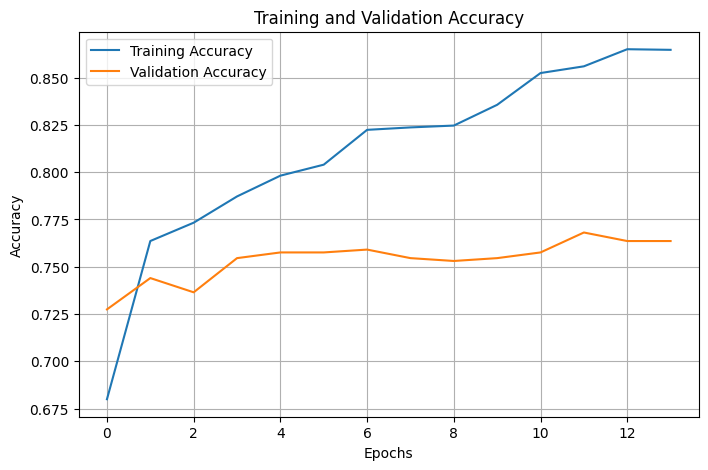

In [63]:

# Plot training and validation accuracy
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()

Observation: The graph compares training and validation accuracy across epochs. Increasing, closely aligned curves indicate effective learning, while a large gap may suggest overfitting.

7.3 Training / Validation Loss

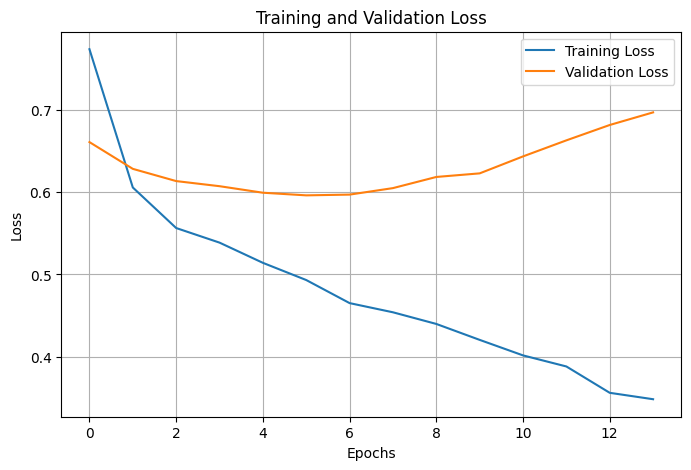

In [64]:
# Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

Observation: The graph compares training and validation loss across epochs. Decreasing, closely aligned curves indicate effective learning, while increasing validation loss alongside decreasing training loss may indicate overfitting.

8. Model Experimentation & Optimization

8.1 Experiment 1 – Baseline

In [65]:
# Baseline ANN
baseline_model = Sequential([
    Input(shape=(X_train_processed.shape[1],)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(3, activation="softmax")  #Predicts Dropout, Enrolled, or Graduate probabilities.
])

baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),  #Updates model weights during training.
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

y_train_enc = np.asarray(y_train, dtype=np.int64)
y_val_enc = np.asarray(y_val, dtype=np.int64)

baseline_history = baseline_model.fit(
    X_train_processed, y_train_enc,
    validation_data=(X_val_processed, y_val_enc),
    epochs=50, batch_size=32,
    callbacks=[EarlyStopping(
        monitor="val_loss", patience=8, restore_best_weights=True
    )],
    verbose=1
)

pred = np.argmax(baseline_model.predict(X_val_processed, verbose=0), axis=1)
print("Validation Accuracy:",
      round(accuracy_score(y_val_enc, pred) * 100, 2), "%")

Epoch 1/50
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6734 - loss: 0.7978 - val_accuracy: 0.7334 - val_loss: 0.6893
Epoch 2/50
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7597 - loss: 0.5836 - val_accuracy: 0.7545 - val_loss: 0.6319
Epoch 3/50
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7897 - loss: 0.5311 - val_accuracy: 0.7590 - val_loss: 0.6127
Epoch 4/50
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8020 - loss: 0.5019 - val_accuracy: 0.7636 - val_loss: 0.6069
Epoch 5/50
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8098 - loss: 0.4802 - val_accuracy: 0.7681 - val_loss: 0.6055
Epoch 6/50
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8204 - loss: 0.4610 - val_accuracy: 0.7636 - val_loss: 0.6086
Epoch 7/50
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8259 - loss: 0.4429 - val_accuracy: 0.7620 - val_loss: 0.6135
Epoch 8/50
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8327 - loss: 0.4252 - val_accuracy: 0.7651 - val_loss:

The baseline ANN uses two hidden layers with ReLU activation and a Softmax output layer to classify student outcomes. Early Stopping helps prevent unnecessary training, while validation accuracy measures the model’s predictive performance.

Baseline Training Graph

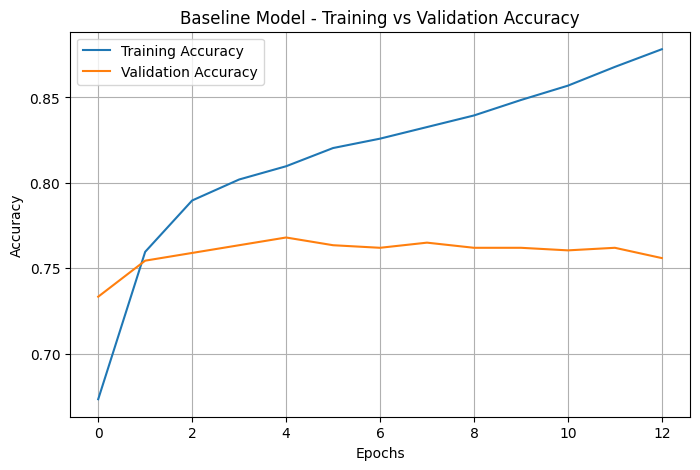

In [66]:
plt.figure(figsize=(8, 5))

plt.plot(
    baseline_history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    baseline_history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('Baseline Model - Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()

the Training Accuracy vs Validation Accuracy for your baseline ANN model in your Student Dropout and Academic Success Prediction project.

Baseline Loss Graph

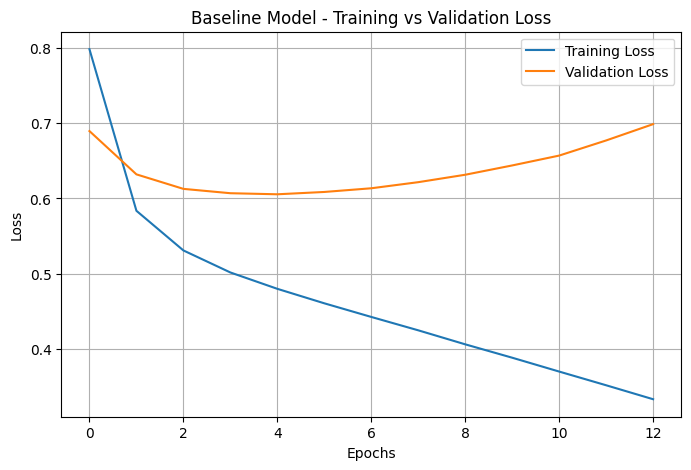

In [67]:
plt.figure(figsize=(8, 5))

plt.plot(
    baseline_history.history['loss'],
    label='Training Loss'
)

plt.plot(
    baseline_history.history['val_loss'],
    label='Validation Loss'
)

plt.title('Baseline Model - Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

the Training Loss vs Validation Loss for your baseline ANN model in your Student Dropout and Academic Success Prediction project.

Changes: Built a baseline ANN with two hidden layers (64 and 32 neurons), ReLU and Softmax activations, Adam optimizer, and Sparse Categorical Crossentropy. Trained for 30 epochs with a batch size of 32 without regularization.

Results: The baseline model established a performance benchmark. Training and validation accuracy were monitored to identify potential improvements, including Dropout, additional neurons, and Early Stopping.

8.2 Experiment 2 – Model Improvement

>



In [68]:
# Experiment 2: deeper ANN with dropout
improved_model = Sequential([
    Input(shape=(X_train_processed.shape[1],)),
    Dense(128, activation="relu"),
    Dropout(0.30),
    Dense(64, activation="relu"),
    Dropout(0.20),
    Dense(32, activation="relu"),
    Dense(len(le.classes_), activation="softmax")
])

improved_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",  #Calculates classification loss for integer labels.
    metrics=["accuracy"]
)

# Targets are already 1-D integer class labels.
y_train_encoded = np.asarray(y_train, dtype=np.int64)
y_val_encoded = np.asarray(y_val, dtype=np.int64)

improved_history = improved_model.fit(
    X_train_processed, y_train_encoded,
    validation_data=(X_val_processed, y_val_encoded),
    epochs=75,
    batch_size=32,
    callbacks=[EarlyStopping(monitor="val_loss", patience=8,
                             restore_best_weights=True)],
    verbose=1
)

improved_val_pred = np.argmax(
    improved_model.predict(X_val_processed, verbose=0), axis=1
)
improved_accuracy = accuracy_score(y_val_encoded, improved_val_pred)
print("Improved ANN validation accuracy:", round(improved_accuracy * 100, 2), "%")

Epoch 1/75
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6528 - loss: 0.8249 - val_accuracy: 0.7364 - val_loss: 0.6821
Epoch 2/75
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7455 - loss: 0.6275 - val_accuracy: 0.7395 - val_loss: 0.6396
Epoch 3/75
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7623 - loss: 0.5810 - val_accuracy: 0.7515 - val_loss: 0.6220
Epoch 4/75
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7823 - loss: 0.5511 - val_accuracy: 0.7530 - val_loss: 0.6156
Epoch 5/75
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7891 - loss: 0.5253 - val_accuracy: 0.7651 - val_loss: 0.6063
Epoch 6/75
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7984 - loss: 0.5011 - val_accuracy: 0.7666 - val_loss: 0.6080
Epoch 7/75
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8117 - loss: 0.4888 - val_accuracy: 0.7756 - val_loss: 0.6077
Epoch 8/75
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8098 - loss: 0.4612 - val_accuracy: 0.7711 - val_loss:

Training / Validation Accuracy

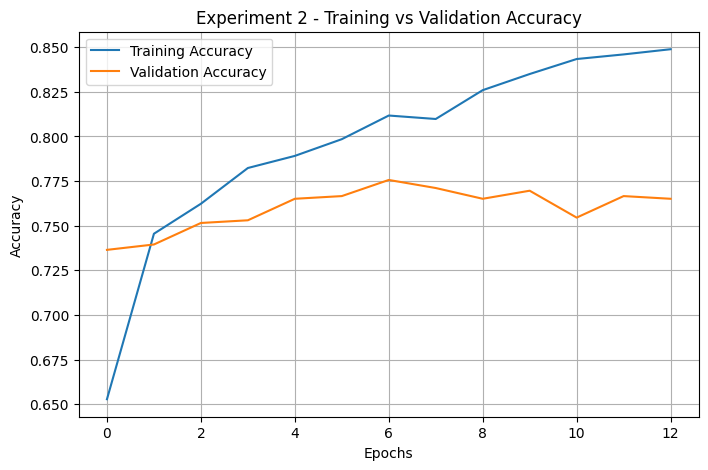

In [69]:

plt.figure(figsize=(8, 5))

plt.plot(
    improved_history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    improved_history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('Experiment 2 - Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()

the Training Accuracy vs Validation Accuracy for Experiment 2 (Improved ANN) in your Student Dropout and Academic Success Prediction project.

Training / Validation Loss

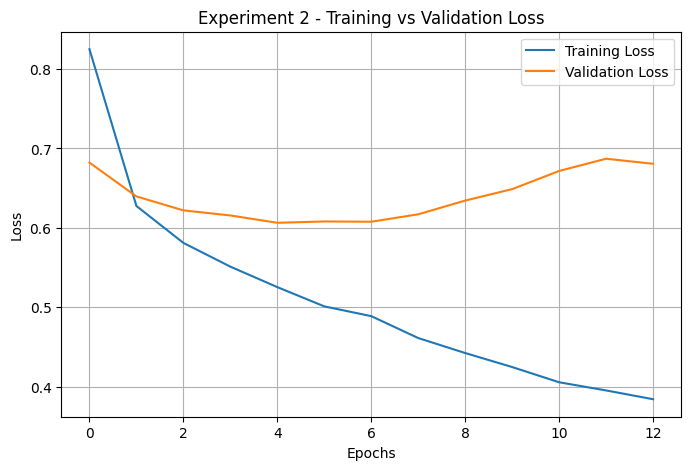

In [70]:
plt.figure(figsize=(8, 5))

plt.plot(
    improved_history.history['loss'],
    label='Training Loss'
)

plt.plot(
    improved_history.history['val_loss'],
    label='Validation Loss'
)

plt.title('Experiment 2 - Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

the Training Loss vs Validation Loss for Experiment 2 (Improved ANN) in your Student Dropout and Academic Success Prediction project.

Changes: Increased the ANN to three hidden layers (128, 64, and 32 neurons). Added Dropout (0.30 and 0.20) and Early Stopping. Used Adam with a learning rate of 0.001 and trained for up to 50 epochs with a batch size of 32.

Results: The improved ANN aimed to reduce overfitting and improve generalization. Early Stopping helped prevent unnecessary training. The model was selected for further test evaluation using accuracy, a classification report, and a confusion matrix.

8.3 Experiment 3 – Hyperparameter / Fine-Tuning



In [71]:
# Experiment 3: regularized ANN with a lower learning rate
tuned_model = Sequential([
    Input(shape=(X_train_processed.shape[1],)),
    Dense(128, activation="relu", kernel_regularizer=l2(0.001)), #Learns patterns at different levels.
    Dropout(0.30),
    Dense(64, activation="relu", kernel_regularizer=l2(0.001)),  #Randomly disables some neurons during training to reduce overfitting.
    Dropout(0.20),
    Dense(32, activation="relu", kernel_regularizer=l2(0.001)),
    Dense(len(le.classes_), activation="softmax")
])

tuned_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Targets are already 1-D integer class labels.
y_train_encoded = np.asarray(y_train, dtype=np.int64)
y_val_encoded = np.asarray(y_val, dtype=np.int64)

tuned_history = tuned_model.fit(
    X_train_processed, y_train_encoded,
    validation_data=(X_val_processed, y_val_encoded),
    epochs=100,
    batch_size=32,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),#Stops training when validation loss fails to improve.
        ReduceLROnPlateau(monitor="val_loss", patience=3,
                          factor=0.5, min_lr=1e-5)
    ],
    verbose=1
)

tuned_val_pred = np.argmax(
    tuned_model.predict(X_val_processed, verbose=0), axis=1
)
tuned_accuracy = accuracy_score(y_val_encoded, tuned_val_pred)
print("Fine-tuned ANN validation accuracy:", round(tuned_accuracy * 100, 2), "%")

Epoch 1/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6298 - loss: 1.1344 - val_accuracy: 0.6898 - val_loss: 0.9817 - learning_rate: 5.0000e-04
Epoch 2/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7206 - loss: 0.9006 - val_accuracy: 0.7274 - val_loss: 0.8810 - learning_rate: 5.0000e-04
Epoch 3/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7461 - loss: 0.8226 - val_accuracy: 0.7334 - val_loss: 0.8380 - learning_rate: 5.0000e-04
Epoch 4/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7668 - loss: 0.7711 - val_accuracy: 0.7455 - val_loss: 0.8086 - learning_rate: 5.0000e-04
Epoch 5/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7687 - loss: 0.7460 - val_accuracy: 0.7530 - val_loss: 0.7955 - learning_rate: 5.0000e-04
Epoch 6/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7820 - loss: 0.7131 - val_accuracy: 0.7605 - val_loss: 0.7776 - learning_rate: 5.0000e-04
Epoch 7/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7852 

Regularization may improve generalization, but it does not guarantee higher accuracy. Compare the models using validation accuracy, macro F1-score, and a confusion matrix. Select the model using validation results, then use your held-out test set for the final evaluation.

Training / Validation Accuracy

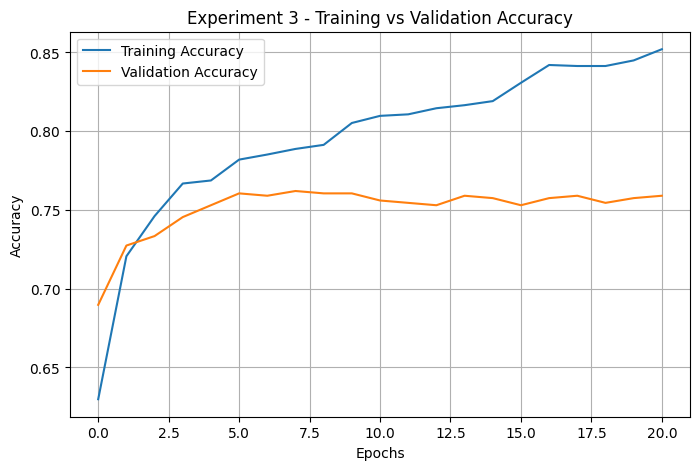

In [72]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    tuned_history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    tuned_history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('Experiment 3 - Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()

This code plots the Training Accuracy vs Validation Accuracy for Experiment 3 (Tuned ANN) in your Student Dropout and Academic Success Prediction project.

Training / Validation Loss

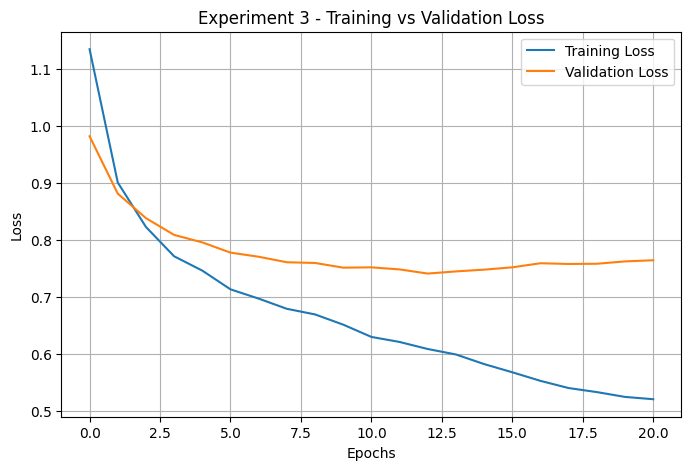

In [73]:
plt.figure(figsize=(8, 5))

plt.plot(
    tuned_history.history['loss'],
    label='Training Loss'
)

plt.plot(
    tuned_history.history['val_loss'],
    label='Validation Loss'
)

plt.title('Experiment 3 - Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

the Training Loss vs Validation Loss for Experiment 3 (Tuned ANN) in your Student Dropout and Academic Success Prediction project.

Compare All 3 Experiments

In [74]:
from sklearn.metrics import accuracy_score
import numpy as np

# Compare the first three ANN experiments on the same validation labels.
y_val_true = np.asarray(y_val, dtype=np.int64)
ann_validation_results = {
    "Baseline ANN": accuracy_score(y_val_true, np.argmax(baseline_model.predict(X_val_processed, verbose=0), axis=1)),
    "Improved ANN": accuracy_score(y_val_true, np.argmax(improved_model.predict(X_val_processed, verbose=0), axis=1)),
    "Fine-Tuned ANN": accuracy_score(y_val_true, np.argmax(tuned_model.predict(X_val_processed, verbose=0), axis=1))
}

print("ANN VALIDATION PERFORMANCE")
for name, score in ann_validation_results.items():
    print(f"{name}: {score * 100:.2f}%")

best_ann_name = max(ann_validation_results, key=ann_validation_results.get)
print("\nBest of first three ANN experiments:", best_ann_name)


ANN VALIDATION PERFORMANCE
Baseline ANN: 76.81%
Improved ANN: 76.51%
Fine-Tuned ANN: 75.30%

Best of first three ANN experiments: Baseline ANN


Experiment 1: Basic ANN
→ Experiment 2: Deeper ANN + Dropout + Early Stopping
→ Experiment 3: Lower learning rate + L2 Regularization + Fine-Tuning.

8.4 Optimization Techniques



In [75]:
# 8.4 Optimization techniques: regularization, dropout, early stopping,
# and learning-rate reduction.
optimized_model = Sequential([
    Input(shape=(X_train_processed.shape[1],)),
    Dense(128, activation="relu", kernel_regularizer=l2(0.001)),
    Dropout(0.30),
    Dense(64, activation="relu", kernel_regularizer=l2(0.001)),
    Dropout(0.20),
    Dense(32, activation="relu", kernel_regularizer=l2(0.001)),
    Dense(len(le.classes_), activation="softmax")
])

optimized_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Targets are already 1-D integer class labels.
y_train_encoded = np.asarray(y_train, dtype=np.int64)
y_val_encoded = np.asarray(y_val, dtype=np.int64)

# Train the optimized model
optimization_history = optimized_model.fit(
    X_train_processed, y_train_encoded,
    validation_data=(X_val_processed, y_val_encoded),
    epochs=100,
    batch_size=32,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", patience=3,
                          factor=0.5, min_lr=1e-5)
    ],
    verbose=1
)
# Predict validation classes
optimized_val_pred = np.argmax(
    optimized_model.predict(X_val_processed, verbose=0), axis=1
)
# Calculate validation accuracy
optimized_val_accuracy = accuracy_score(y_val_encoded, optimized_val_pred)
print("Optimized ANN validation accuracy:",
      round(optimized_val_accuracy * 100, 2), "%")

Epoch 1/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6292 - loss: 1.1162 - val_accuracy: 0.7048 - val_loss: 0.9652 - learning_rate: 5.0000e-04
Epoch 2/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7225 - loss: 0.8955 - val_accuracy: 0.7380 - val_loss: 0.8817 - learning_rate: 5.0000e-04
Epoch 3/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7468 - loss: 0.8134 - val_accuracy: 0.7485 - val_loss: 0.8314 - learning_rate: 5.0000e-04
Epoch 4/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7665 - loss: 0.7677 - val_accuracy: 0.7560 - val_loss: 0.8035 - learning_rate: 5.0000e-04
Epoch 5/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7716 - loss: 0.7416 - val_accuracy: 0.7515 - val_loss: 0.7899 - learning_rate: 5.0000e-04
Epoch 6/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7787 - loss: 0.7134 - val_accuracy: 0.7545 - val_loss: 0.7744 - learning_rate: 5.0000e-04
Epoch 7/100
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7904 

Observation: The optimized ANN model uses L2 regularization, Dropout, Early Stopping, and learning-rate reduction to reduce overfitting and improve generalization. Validation accuracy is used to evaluate its performance on unseen validation data.

Techniques covered by this code

Technique	Implementation

Dropout	Dropout(0.30) and Dropout(0.20)

Early Stopping	EarlyStopping()

Data Augmentation	Not applicable

Hyperparameter Tuning	Learning rate, epochs, batch size, layers/neurons

Fine-Tuning	Learning rate 0.0005

Regularization	l2(0.001)

9. Model Evaluation

9.1 Evaluation Metrics
Classification / NLP:


Accuracy
Precision
Recall
F1 Score
Confusion Matrix


Generator Loss
Discriminator Loss
Image Quality
Image Diversity

In [76]:
# Compare all candidate models using validation accuracy, then evaluate only the winner on test data.
import numpy as np
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_val = np.asarray(y_val, dtype=np.int64)
y_test = np.asarray(y_test, dtype=np.int64)

candidate_models = {
    "Logistic Regression": {
        "kind": "sklearn", "model": best_logistic_model,
        "val_accuracy": accuracy_score(y_val, best_logistic_model.predict(X_val))
    },
    "Random Forest": {
        "kind": "sklearn", "model": best_rf_model,
        "val_accuracy": accuracy_score(y_val, best_rf_model.predict(X_val))
    },
    "XGBoost": {
        "kind": "sklearn", "model": best_xgb_model,
        "val_accuracy": accuracy_score(y_val, best_xgb_model.predict(X_val))
    },
    "Primary ANN": {
        "kind": "keras", "model": model,
        "val_accuracy": main_val_accuracy
    },
    "Baseline ANN": {
        "kind": "keras", "model": baseline_model,
        "val_accuracy": ann_validation_results["Baseline ANN"]
    },
    "Improved ANN": {
        "kind": "keras", "model": improved_model,
        "val_accuracy": ann_validation_results["Improved ANN"]
    },
    "Fine-Tuned ANN": {
        "kind": "keras", "model": tuned_model,
        "val_accuracy": ann_validation_results["Fine-Tuned ANN"]
    },
    "Optimized ANN": {
        "kind": "keras", "model": optimized_model,
        "val_accuracy": optimized_val_accuracy
    }
}

print("--- Model Validation Accuracies ---")
for name, item in candidate_models.items():
    print(f"{name}: {item['val_accuracy'] * 100:.2f}%")

selected_model_name = max(candidate_models, key=lambda name: candidate_models[name]["val_accuracy"])
selected_model = candidate_models[selected_model_name]
print(f"\nSelected model (validation accuracy): {selected_model_name}")

if selected_model["kind"] == "sklearn":
    y_test_pred = selected_model["model"].predict(X_test)
else:
    y_test_pred = np.argmax(
        selected_model["model"].predict(X_test_processed, verbose=0), axis=1
    )

y_test_pred = np.asarray(y_test_pred, dtype=np.int64).ravel()
test_accuracy = accuracy_score(y_test, y_test_pred)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(
    y_test, y_test_pred,
    labels=np.arange(len(le.classes_)),
    target_names=le.classes_,
    zero_division=0
))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_test_pred, labels=np.arange(len(le.classes_))))


--- Model Validation Accuracies ---
Logistic Regression: 76.96%
Random Forest: 74.70%
XGBoost: 75.90%
Primary ANN: 75.75%
Baseline ANN: 76.81%
Improved ANN: 76.51%
Fine-Tuned ANN: 75.30%
Optimized ANN: 76.05%

Selected model (validation accuracy): Logistic Regression
Test Accuracy: 79.52%

Classification Report:
              precision    recall  f1-score   support

     Dropout       0.84      0.79      0.81       214
    Enrolled       0.61      0.43      0.50       119
    Graduate       0.81      0.93      0.87       331

    accuracy                           0.80       664
   macro avg       0.75      0.72      0.73       664
weighted avg       0.78      0.80      0.79       664

Confusion Matrix:
 [[169  21  24]
 [ 21  51  47]
 [ 11  12 308]]


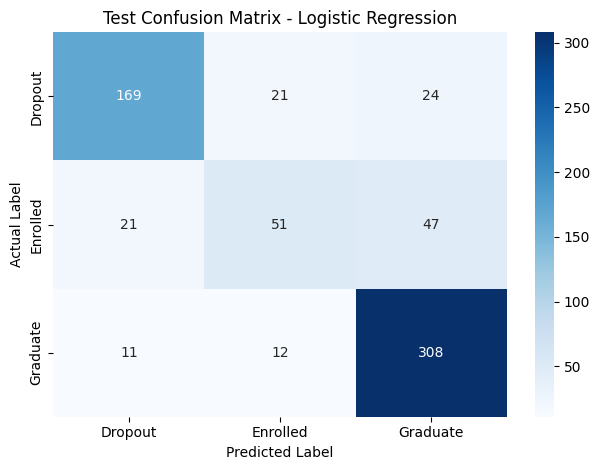

In [77]:
# Plot the selected model's test confusion matrix.
cm = confusion_matrix(y_test, y_test_pred, labels=np.arange(len(le.classes_)))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title(f"Test Confusion Matrix - {selected_model_name}")
plt.tight_layout()
plt.show()




Justification: Accuracy, Precision, Recall, F1-score, and Confusion Matrix are appropriate metrics for evaluating the ANN model's three-class classification performance: Dropout, Enrolled, and Graduate.

### 9.2 Model Comparison

The model comparison is generated from validation results in the evaluation code. Report the measured scores from your latest complete notebook run rather than copying earlier accuracy values. The final test set is used only after choosing the model using validation performance.


### 9.3 Best Model Selection

**Selected model:** Determined from validation accuracy in the final evaluation code.

**Reason:** Model selection is based on validation performance. The held-out test set is used only for the final unbiased evaluation. Do not claim that accuracy exceeds 90% unless the latest test result actually demonstrates it.


In [78]:
# Error analysis for the selected model on the held-out test set.
y_true = np.asarray(y_test, dtype=np.int64).ravel()
y_pred = np.asarray(y_test_pred, dtype=np.int64).ravel()

cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(le.classes_)))
print("Confusion Matrix:\n", cm)
print(classification_report(
    y_true, y_pred,
    labels=np.arange(len(le.classes_)),
    target_names=le.classes_,
    zero_division=0
))

misclassified = np.where(y_true != y_pred)[0]
error_analysis = pd.DataFrame({
    "Actual": le.inverse_transform(y_true[misclassified]),
    "Predicted": le.inverse_transform(y_pred[misclassified])
})
print("\nTotal misclassified samples:", len(misclassified))
print("Total test samples:", len(y_true))
print("\nFirst 20 misclassified outcomes:")
display(error_analysis.head(20))


Confusion Matrix:
 [[169  21  24]
 [ 21  51  47]
 [ 11  12 308]]
              precision    recall  f1-score   support

     Dropout       0.84      0.79      0.81       214
    Enrolled       0.61      0.43      0.50       119
    Graduate       0.81      0.93      0.87       331

    accuracy                           0.80       664
   macro avg       0.75      0.72      0.73       664
weighted avg       0.78      0.80      0.79       664


Total misclassified samples: 136
Total test samples: 664

First 20 misclassified outcomes:


,Actual,Predicted
0,Graduate,Dropout
1,Enrolled,Graduate
2,Graduate,Enrolled
3,Enrolled,Graduate
4,Enrolled,Graduate
5,Enrolled,Graduate
6,Dropout,Graduate
7,Graduate,Enrolled
8,Enrolled,Graduate
9,Dropout,Graduate


**Observation:** Use the confusion matrix and classification report generated by the final run. Discuss which class has the lowest recall or F1-score and avoid assuming that any class performs best before checking the results.


9.5 Overfitting / Underfitting

In [79]:
# Plot learning curves only when the selected model is an ANN.
ann_candidates = {
    "Primary ANN": (model, history),
    "Baseline ANN": (baseline_model, baseline_history),
    "Improved ANN": (improved_model, improved_history),
    "Fine-Tuned ANN": (tuned_model, tuned_history),
    "Optimized ANN": (optimized_model, optimization_history)
}

if selected_model_name in ann_candidates:
    plot_model, plot_history = ann_candidates[selected_model_name]
    plt.figure(figsize=(8, 5))
    plt.plot(plot_history.history["accuracy"], label="Training Accuracy")
    plt.plot(plot_history.history["val_accuracy"], label="Validation Accuracy")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.title(f"Training vs Validation Accuracy - {selected_model_name}")
    plt.legend()
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(plot_history.history["loss"], label="Training Loss")
    plt.plot(plot_history.history["val_loss"], label="Validation Loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.title(f"Training vs Validation Loss - {selected_model_name}")
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print("The selected model is not an ANN; ANN learning curves do not represent the selected model.")

print("Selected model:", selected_model_name)
print(f"Validation accuracy: {candidate_models[selected_model_name]['val_accuracy'] * 100:.2f}%")
print(f"Final test accuracy: {test_accuracy * 100:.2f}%")


The selected model is not an ANN; ANN learning curves do not represent the selected model.
Selected model: Logistic Regression
Validation accuracy: 76.96%
Final test accuracy: 79.52%


Observation: The training and validation accuracy and loss graphs are used to analyze overfitting and underfitting in the selected ANN model. The final test accuracy measures its performance on unseen data.

PHASE 4 – DEPLOYMENT & DOCUMENTATION

10. Model Export

In [80]:

import os
import json
import joblib

artifact_dir = "artifacts"
os.makedirs(artifact_dir, exist_ok=True)

joblib.dump(le, os.path.join(artifact_dir, "label_encoder.pkl"))
joblib.dump(preprocessor, os.path.join(artifact_dir, "preprocessor.pkl"))
joblib.dump(list(X.columns), os.path.join(artifact_dir, "feature_columns.pkl"))

if selected_model["kind"] == "keras":
    model_path = os.path.join(artifact_dir, "student_model.keras")
    selected_model["model"].save(model_path)
    export_format = "keras"
else:
    model_path = os.path.join(artifact_dir, "selected_sklearn_pipeline.joblib")
    joblib.dump(selected_model["model"], model_path)
    export_format = "sklearn_pipeline"

metadata = {
    "selected_model_name": selected_model_name,
    "model_format": export_format,
    "validation_accuracy": float(selected_model["val_accuracy"]),
    "test_accuracy": float(test_accuracy),
    "class_names": [str(c) for c in le.classes_],
    "feature_columns": list(X.columns)
}
with open(os.path.join(artifact_dir, "model_metadata.json"), "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Selected model saved:", model_path)
print("Selected model:", selected_model_name)
print("Preprocessor, label encoder, feature columns, and metadata saved in:", artifact_dir)


Selected model saved: artifacts/selected_sklearn_pipeline.joblib
Selected model: Logistic Regression
Preprocessor, label encoder, feature columns, and metadata saved in: artifacts


11. API Deployment

11.1 Technology Used



 FastAPI

In [81]:
from fastapi import FastAPI
from pydantic import BaseModel

app = FastAPI()

class Student(BaseModel):
    age: int
    previous_grade: float

@app.get("/")
def home():
    return {"message": "Student Prediction API"}

@app.post("/predict")
def predict(student: Student):
    # Connect your trained model here
    return {
        "age": student.age,
        "previous_grade": student.previous_grade,
        "message": "Input received successfully"
    }

In [82]:
print("Preprocessor exists:", "preprocessor" in globals())
print("Label encoder exists:", "le" in globals())
print("Features exist:", "X" in globals())
print("Selected model exists:", "selected_model" in globals())

if "selected_model" in globals():
    print("Selected model details:", selected_model.keys())

Preprocessor exists: True
Label encoder exists: True
Features exist: True
Selected model exists: True
Selected model details: dict_keys(['kind', 'model', 'val_accuracy'])


In [83]:

import os
import joblib
import shutil

artifact_dir = "/content/artifacts"
os.makedirs(artifact_dir, exist_ok=True)

# Save preprocessing objects
joblib.dump(preprocessor, os.path.join(
    artifact_dir, "preprocessor.pkl"
))

joblib.dump(le, os.path.join(
    artifact_dir, "label_encoder.pkl"
))

joblib.dump(list(X.columns), os.path.join(
    artifact_dir, "feature_columns.pkl"
))

# Save the selected model according to its type
if selected_model["kind"] == "keras":
    selected_model["model"].save(
        os.path.join(artifact_dir, "student_model.keras")
    )
else:
    joblib.dump(
        selected_model["model"],
        os.path.join(artifact_dir, "student_model.pkl")
    )

# Display saved files and sizes
for filename in os.listdir(artifact_dir):
    path = os.path.join(artifact_dir, filename)
    print(filename, "-", round(os.path.getsize(path) / 1024, 2), "KB")

print("Selected model type:", selected_model["kind"])
print("Validation accuracy:", selected_model["val_accuracy"])


label_encoder.pkl - 0.49 KB
selected_sklearn_pipeline.joblib - 15.03 KB
student_model.pkl - 15.03 KB
preprocessor.pkl - 8.65 KB
feature_columns.pkl - 0.93 KB
model_metadata.json - 1.36 KB
Selected model type: sklearn
Validation accuracy: 0.7695783132530121


In [85]:
from google.colab import files
import shutil

shutil.make_archive(
    "/content/artifacts",
    "zip",
    "/content/artifacts"
)

files.download("/content/artifacts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>